In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.utils.paths import EXTERNAL_DIR, VISUALIZATION_DIR
from src.models.baselines.gcn_lstm import get_adjacency

In [2]:
def w_adj_plot(df):
    DISTANCE_MATRIX_DIR = VISUALIZATION_DIR / "distance_matrix"
    DISTANCE_MATRIX_DIR.mkdir(parents=True, exist_ok=True)
    df.to_csv(os.path.join(EXTERNAL_DIR, f"weighted_adjacency_matrix.csv"), columns=df.columns, index=True)

    plt.figure(figsize=(18,12))
    sns.heatmap(data=df, cmap='coolwarm', cbar_kws={'label': f'Weights'}, annot=True)
    plt.title(f"Weighted Adjacency Matrix between AQI stations", fontsize=24, pad=8, fontweight='bold')
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.ylabel("AQI station", fontsize=12, fontweight='bold')
    plt.xlabel("AQI station", fontsize=12, fontweight='bold')
    plt.tight_layout()

    plt.savefig(os.path.join(DISTANCE_MATRIX_DIR, f"weighted_adjacency_matrix.png"), dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

In [3]:
def get_distance():
    dist_path = os.path.join(EXTERNAL_DIR, "Haversine_distance_matrix.csv")  # (N, N) haversine, km
    dist = pd.read_csv(dist_path)
    dist = dist.set_index(dist.columns[0])
    stations = dist.columns
    return dist.to_numpy(), stations

def build_weighted_adj(dist, sigma=None, eps=0.01):
    n = dist.shape[0]
    off_diag = dist[~np.eye(n, dtype=bool)]
    if sigma is None:
        sigma = off_diag.std()
    w = np.exp(-(dist ** 2) / sigma ** 2) # can be multiplied by 2 also
    w[w < eps] = 0.0
    w = w.astype(np.float32)
    threshold = round(float(np.sqrt(-sigma ** 2 * np.log(eps))), 2)

    print(f"sigma={sigma:.2f}, eps={eps}, cutoff distance={threshold} (same units as haversine)")
    return w

In [4]:
dist, stations = get_distance()
assert dist is not None, "distance matrix missing"

w_adj_matrix = build_weighted_adj(dist)
w_adj_matrix_df = pd.DataFrame(w_adj_matrix, index=stations, columns=stations).round(4)
# self.register_buffer("normalized_adj",
#                      normalize_adjacency(torch.as_tensor(w_adj_matrix, dtype=torch.float32)))

sigma=8.66, eps=0.01, cutoff distance=18.59 (same units as haversine)


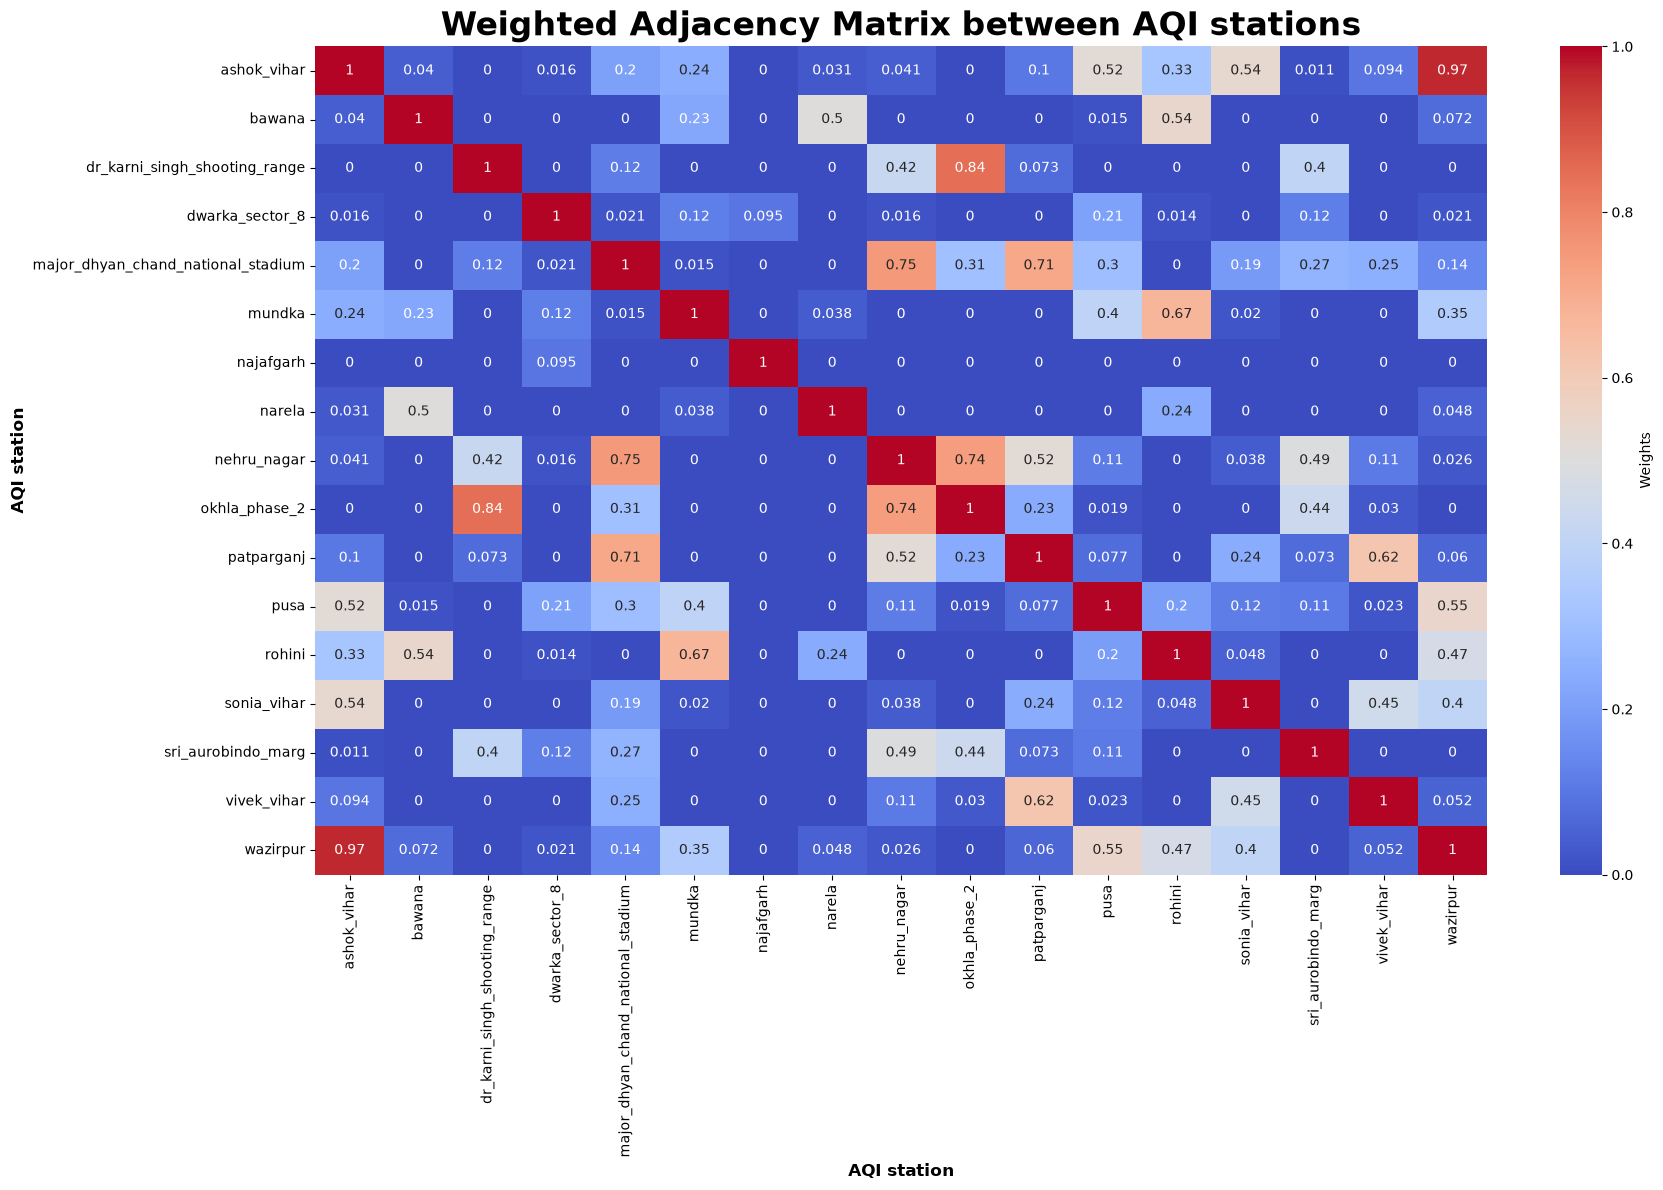

In [5]:
w_adj_plot(w_adj_matrix_df)